# Task 70: Interactive Prediction Confidence Distribution & Visualization

Manually compute probability distributions and epistemic Shannon entropy, evaluate clinical decision thresholds, and explore confidence margins with animated bar distributions.


=== CLINICAL PROFILE CONFIDENCE DISTRIBUTION EVALUATION ===

Patient A (Young, Normal Vitals, Low Risk)
P(Healthy)=0.0138 | P(Disease)=0.9862 | Confidence=98.6% | Entropy=0.105b | Tier=High Confidence

Patient B (Borderline Clinical Presentation)
P(Healthy)=0.5475 | P(Disease)=0.4525 | Confidence=54.7% | Entropy=0.993b | Tier=Low / Borderline Confidence

Patient C (Severe Angina & Multiple Vessel Defect)
P(Healthy)=0.9867 | P(Disease)=0.0133 | Confidence=98.7% | Entropy=0.102b | Tier=High Confidence

=== SUMMARY TABLE ACROSS CLINICAL PROFILES ===
                                           Profile  P(Healthy)  P(Disease)  Confidence  Margin (Δ)  Entropy (bits)             Confidence Tier
        Patient A (Young, Normal Vitals, Low Risk)    0.013834    0.986166    0.986166    0.972332        0.105254             High Confidence
      Patient B (Borderline Clinical Presentation)    0.547497    0.452503    0.547497    0.094994        0.993481 Low / Borderline Confidence
Patient C (Severe 

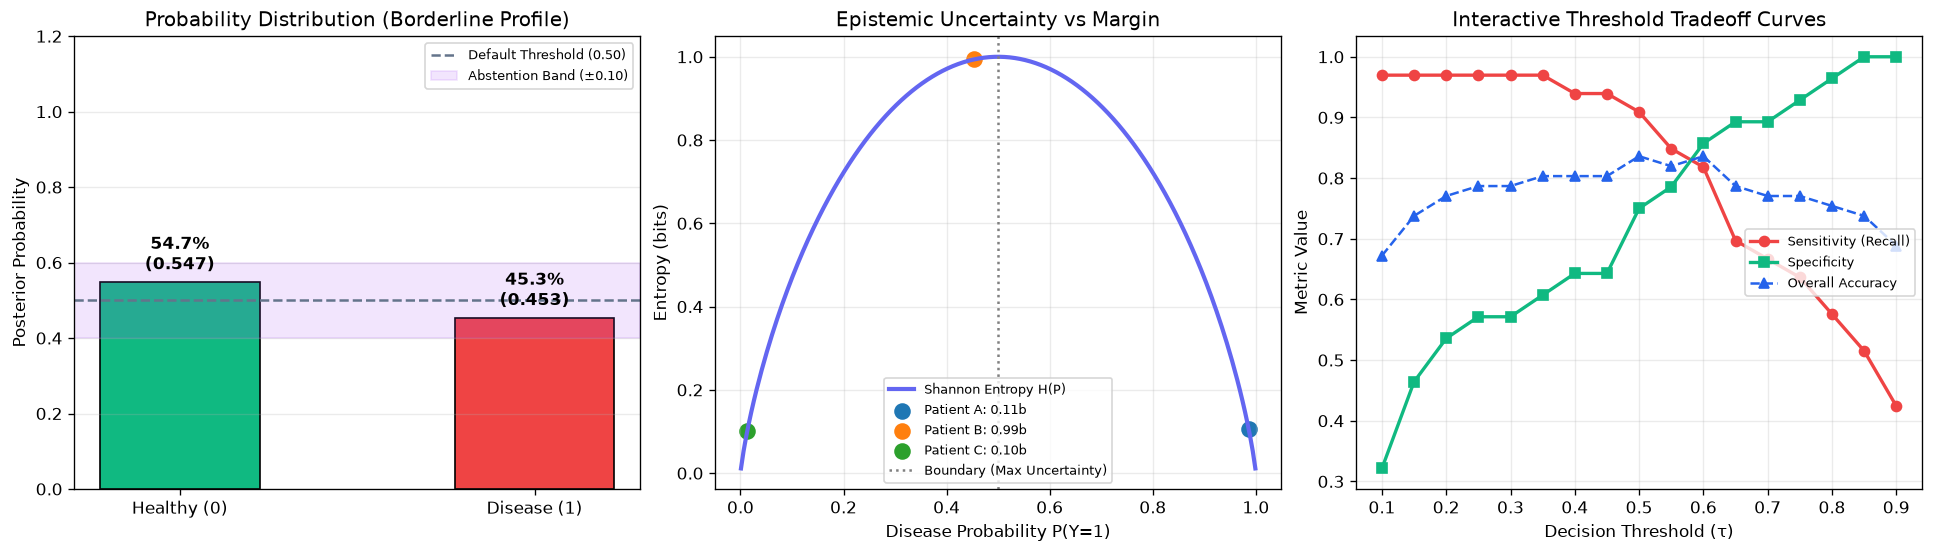

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

paths = [Path("heart.csv"), Path("Task_70_Confidence_Distribution_Visualization/heart.csv"), Path("Heart_Disease_Tasks/Task_70_Confidence_Distribution_Visualization/heart.csv")]
data = pd.read_csv(next(p for p in paths if p.is_file())).drop_duplicates().reset_index(drop=True)
features = [c for c in ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach", "exang", "oldpeak", "slope", "ca", "thal"] if c in data]
X, y = data[features].to_numpy(float), data["target"].to_numpy(int)

# Stratified Split & Model
def stratified_split(X, y, test_size=0.2, seed=70):
    rng = np.random.default_rng(seed)
    train_idx, test_idx = [], []
    for label in np.unique(y):
        idx = np.flatnonzero(y == label)
        rng.shuffle(idx)
        cut = int(round(len(idx) * (1 - test_size)))
        train_idx.extend(idx[:cut])
        test_idx.extend(idx[cut:])
    train_idx, test_idx = np.array(train_idx), np.array(test_idx)
    rng.shuffle(train_idx)
    rng.shuffle(test_idx)
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

X_train, X_test, y_train, y_test = stratified_split(X, y, test_size=0.2, seed=70)
mu = X_train.mean(axis=0)
sd = np.where(X_train.std(axis=0) == 0, 1.0, X_train.std(axis=0))
X_train_s = (X_train - mu) / sd
X_test_s = (X_test - mu) / sd

class ScratchLogistic:
    def fit(self, X, y, lr=0.06, iters=1400, l2=0.02):
        self.w = np.zeros(X.shape[1])
        self.b = 0.0
        n = len(y)
        for _ in range(iters):
            z = np.clip(X @ self.w + self.b, -35, 35)
            p = 1.0 / (1.0 + np.exp(-z))
            err = p - y
            self.w -= lr * ((X.T @ err) / n + l2 * self.w)
            self.b -= lr * err.mean()
        return self
    def predict_proba(self, X):
        z = np.clip(X @ self.w + self.b, -35, 35)
        return 1.0 / (1.0 + np.exp(-z))
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

model = ScratchLogistic().fit(X_train_s, y_train)

# Manual Confidence Distribution Computation
def compute_confidence_distribution(prob_presence):
    p1 = float(np.clip(prob_presence, 1e-7, 1.0 - 1e-7))
    p0 = 1.0 - p1
    margin = abs(p1 - 0.5) * 2.0
    entropy = float(-(p0 * np.log2(p0) + p1 * np.log2(p1)))
    confidence = max(p0, p1)
    predicted_class = 1 if p1 >= 0.5 else 0

    if confidence >= 0.80:
        tier = "High Confidence"
    elif confidence >= 0.60:
        tier = "Moderate Confidence"
    else:
        tier = "Low / Borderline Confidence"

    return {
        "p0": p0,
        "p1": p1,
        "confidence": confidence,
        "margin": margin,
        "entropy": entropy,
        "tier": tier,
        "predicted_class": predicted_class
    }

# Evaluate sample profiles
profiles = [
    ("Patient A (Young, Normal Vitals, Low Risk)", np.array([39, 0, 2, 115, 175, 0, 0, 172, 0, 0.0, 2, 0, 2], dtype=float)),
    ("Patient B (Borderline Clinical Presentation)", np.array([57, 1, 1, 134, 238, 0, 1, 146, 0, 1.1, 1, 1, 2], dtype=float)),
    ("Patient C (Severe Angina & Multiple Vessel Defect)", np.array([66, 1, 0, 160, 285, 1, 2, 118, 1, 3.4, 1, 2, 3], dtype=float)),
]

profile_evals = []
print("=== CLINICAL PROFILE CONFIDENCE DISTRIBUTION EVALUATION ===")
for name, raw_vec in profiles:
    scaled_vec = (raw_vec - mu) / sd
    p1 = float(model.predict_proba(scaled_vec[None, :])[0])
    res = compute_confidence_distribution(p1)
    profile_evals.append({
        "Profile": name,
        "P(Healthy)": res["p0"],
        "P(Disease)": res["p1"],
        "Confidence": res["confidence"],
        "Margin (Δ)": res["margin"],
        "Entropy (bits)": res["entropy"],
        "Confidence Tier": res["tier"]
    })
    print(f"\n{name}")
    print(f"P(Healthy)={res['p0']:.4f} | P(Disease)={res['p1']:.4f} | Confidence={res['confidence']*100:.1f}% | Entropy={res['entropy']:.3f}b | Tier={res['tier']}")

df_profiles = pd.DataFrame(profile_evals)
print("\n=== SUMMARY TABLE ACROSS CLINICAL PROFILES ===")
print(df_profiles.to_string(index=False))

# Threshold Sensitivity Analysis on Test Cohort (N=61)
test_probs = model.predict_proba(X_test_s)
thresholds = np.linspace(0.10, 0.90, 17)
threshold_metrics = []

for th in thresholds:
    preds = (test_probs >= th).astype(int)
    tp = int(np.sum((y_test == 1) & (preds == 1)))
    tn = int(np.sum((y_test == 0) & (preds == 0)))
    fp = int(np.sum((y_test == 0) & (preds == 1)))
    fn = int(np.sum((y_test == 1) & (preds == 0)))
    sens = tp / (tp + fn) if (tp + fn) else 0.0
    spec = tn / (tn + fp) if (tn + fp) else 0.0
    acc = (tp + tn) / len(y_test)
    f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0.0
    threshold_metrics.append({
        "Threshold (τ)": th,
        "Sensitivity (Recall)": sens,
        "Specificity": spec,
        "Accuracy": acc,
        "F1": f1
    })

df_thresholds = pd.DataFrame(threshold_metrics)
print("\n=== THRESHOLD EXPLORATION & CLINICAL TRADEOFF MATRIX ===")
print(df_thresholds.iloc[::2].to_string(index=False))

# Abstention Zone Impact Analysis (±δ around 0.50)
deltas = [0.00, 0.05, 0.10, 0.15, 0.20]
abstention_rows = []
for d in deltas:
    in_gray = np.abs(test_probs - 0.50) <= d
    decided_idx = ~in_gray
    coverage = np.mean(decided_idx) * 100.0
    if np.sum(decided_idx) > 0:
        decided_acc = np.mean((test_probs[decided_idx] >= 0.50).astype(int) == y_test[decided_idx]) * 100.0
    else:
        decided_acc = 0.0
    abstention_rows.append({
        "Margin (±δ)": d,
        "Uncertainty Band": f"[{0.50 - d:.2f}, {0.50 + d:.2f}]",
        "Coverage (%)": coverage,
        "Abstained Cases": int(np.sum(in_gray)),
        "Decided Accuracy (%)": decided_acc
    })

df_abstention = pd.DataFrame(abstention_rows)
print("\n=== CLINICAL ABSTENTION BAND IMPACT ===")
print(df_abstention.to_string(index=False))

# Visualization
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)

# 1. Manually Computed Probability Distribution for Patient B
b_res = profile_evals[1]
bars = axes[0].bar(["Healthy (0)", "Disease (1)"], [b_res["P(Healthy)"], b_res["P(Disease)"]], color=["#10b981", "#ef4444"], width=0.45, edgecolor="black")
for b in bars:
    h = b.get_height()
    axes[0].text(b.get_x() + b.get_width()/2.0, h + 0.02, f"{h*100:.1f}%\n({h:.3f})", ha="center", va="bottom", fontweight="bold")
axes[0].axhline(0.50, color="#64748b", linestyle="--", linewidth=1.5, label="Default Threshold (0.50)")
axes[0].axhspan(0.40, 0.60, color="#a855f7", alpha=0.15, label="Abstention Band (±0.10)")
axes[0].set_ylim(0, 1.2)
axes[0].set_ylabel("Posterior Probability")
axes[0].set_title("Probability Distribution (Borderline Profile)")
axes[0].legend(loc="upper right", fontsize=8)
axes[0].grid(axis="y", alpha=0.25)

# 2. Shannon Entropy vs Margin Curve
p_range = np.linspace(0.001, 0.999, 200)
h_curve = -(p_range * np.log2(p_range) + (1 - p_range) * np.log2(1 - p_range))
axes[1].plot(p_range, h_curve, color="#6366f1", linewidth=2.5, label="Shannon Entropy H(P)")
for r in profile_evals:
    axes[1].scatter([r["P(Disease)"]], [r["Entropy (bits)"]], s=80, label=f"{r['Profile'][:9]}: {r['Entropy (bits)']:.2f}b")
axes[1].axvline(0.50, color="gray", linestyle=":", label="Boundary (Max Uncertainty)")
axes[1].set_xlabel("Disease Probability P(Y=1)")
axes[1].set_ylabel("Entropy (bits)")
axes[1].set_title("Epistemic Uncertainty vs Margin")
axes[1].legend(loc="lower center", fontsize=7.5)
axes[1].grid(alpha=0.25)

# 3. Sensitivity vs Specificity Tradeoff across Thresholds
axes[2].plot(df_thresholds["Threshold (τ)"], df_thresholds["Sensitivity (Recall)"], marker="o", color="#ef4444", linewidth=2, label="Sensitivity (Recall)")
axes[2].plot(df_thresholds["Threshold (τ)"], df_thresholds["Specificity"], marker="s", color="#10b981", linewidth=2, label="Specificity")
axes[2].plot(df_thresholds["Threshold (τ)"], df_thresholds["Accuracy"], marker="^", color="#2563eb", linewidth=1.5, linestyle="--", label="Overall Accuracy")
axes[2].set_xlabel("Decision Threshold (τ)")
axes[2].set_ylabel("Metric Value")
axes[2].set_title("Interactive Threshold Tradeoff Curves")
axes[2].legend(loc="center right", fontsize=8)
axes[2].grid(alpha=0.25)

plt.show()
